# A spiking network from a synthetic connectome

This tutorial generates a connectome with assemblies (groups of neurons that are more
densely connected among themselves), puts conductance-based neurons on it, drives it
with Poisson input and records the activity. With a measured connectome, you would skip
the first step and start from its weight matrix and cell types.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap

import wiretorch as wt
from wiretorch import visualization as viz
from wiretorch.dataloaders.unsupervised import HomogeneousPoissonSpikeDataLoader
from wiretorch.synthetic_connectome import (
    cell_types,
    topology_generators,
    weight_assigners,
)

viz.use_theme()  # the docs' plot style, light and dark
device = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(0)
torch.manual_seed(0)

## The connectome

There are 400 neurons, 80% excitatory and 20% inhibitory, in 4 assemblies that each
contain both types. Connection probabilities are given for each pair of source and
target types, and are higher within an assembly than between assemblies. The external
inputs are 200 neurons of a single type, connected at random.

In [2]:
N, N_IN, ASSEMBLIES = 400, 200, 4
E, I = 0, 1
types = cell_types.assign_cell_types(N, [0.8, 0.2], num_assemblies=ASSEMBLIES)
input_types = np.zeros(N_IN, dtype=int)

#                     to E    to I
within = [
    [0.10, 0.10],  # from E
    [0.20, 0.20],
]  # from I
between = [[0.03, 0.03], [0.20, 0.20]]
recurrent, assembly = topology_generators.assembly_generator(
    types, types, ASSEMBLIES, within, between
)
feedforward = topology_generators.sparse_graph_generator(
    input_types, types, [[0.12, 0.12]]
)
print(
    "recurrent connections:", recurrent.sum(), " input connections:", feedforward.sum()
)

recurrent connections: 12282  input connections: 9607


Weights are drawn from a log-normal distribution, with a mean and variance for each
pair of types. They are non-negative: whether a connection excites or inhibits is set
by the synapse types below.

<Figure size 495x440 with 1 Axes>
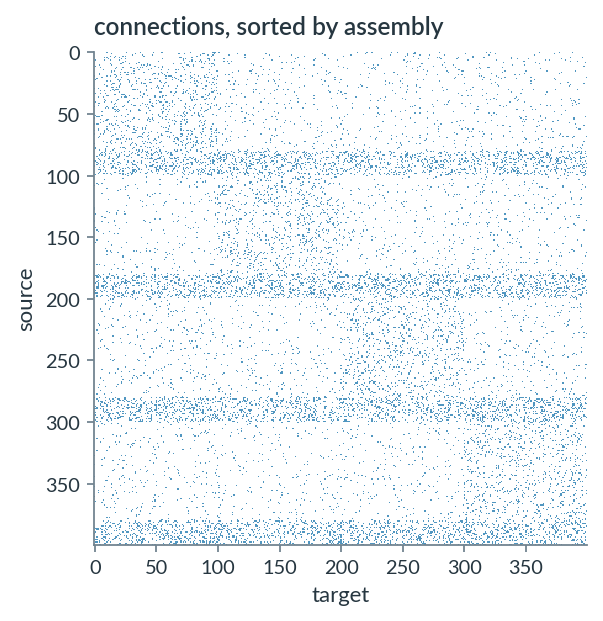
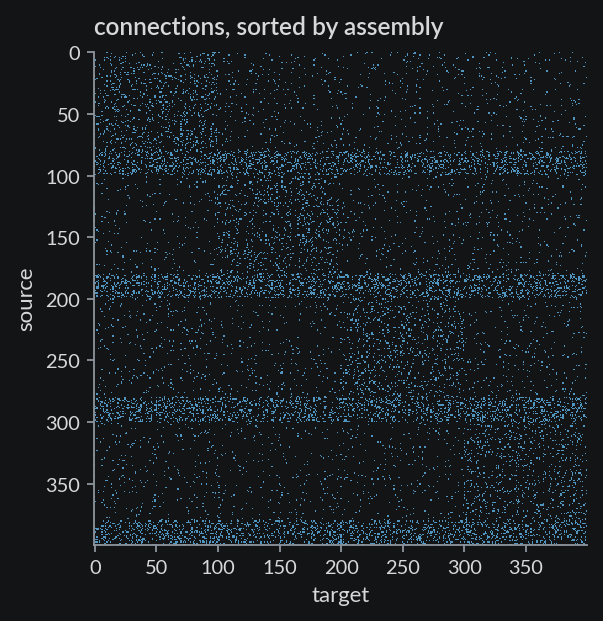

In [3]:
w_rec = weight_assigners.assign_weights_lognormal(
    recurrent,
    types,
    types,
    None,
    w_mu_matrix=[[0.3, 0.3], [1.8, 1.8]],  # mean
    w_sigma_matrix=[[0.09, 0.09], [3.24, 3.24]],  # variance
    parameter_space="linear",
)
w_in = weight_assigners.assign_weights_lognormal(
    feedforward,
    input_types,
    types,
    None,
    [[0.18, 0.18]],
    [[0.03, 0.03]],
    parameter_space="linear",
)

order = np.lexsort((types, assembly))  # by assembly, then type
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(
    w_rec[np.ix_(order, order)] > 0,
    cmap=ListedColormap(["none", viz.theme.BLUE]),
    interpolation="nearest",
)
(
    ax.set_title("connections, sorted by assembly"),
    ax.set_xlabel("target"),
    ax.set_ylabel("source"),
)
plt.show()

## The network

`make_frozen_projections` splits the weight matrices into fixed projections, one for
each pair of types. Each cell type has its physiology and the synapse types it makes:
AMPA for excitatory neurons and inputs (reversal potential 0 mV) and GABA for
inhibitory neurons (−70 mV). `g_clip` caps the conductance of each synapse type, which
keeps the voltage step stable when many inputs arrive at once.

In [4]:
names, input_names = ["E", "I"], ["input"]
rec_projections, in_projections = wt.make_frozen_projections(
    w_rec, w_in, types, input_types, names, input_names
)

AMPA = dict(name="AMPA", tau_rise=0.1, tau_decay=5.0, E_syn=0.0, g_clip=40.0)
model = wt.ConductanceLIFNetwork(
    dt=1.0,  # ms
    rec_projections=rec_projections,
    ff_projections=in_projections,
    cell_type_indices=types,
    cell_type_indices_FF=input_types,
    cell_params=[
        dict(
            name="E",
            cell_id=E,
            tau_mem=85.0,
            theta=-38.0,
            U_reset=-60.0,
            E_L=-60.0,
            g_L=1.35,
        ),
        dict(
            name="I",
            cell_id=I,
            tau_mem=50.0,
            theta=-45.0,
            U_reset=-60.0,
            E_L=-60.0,
            g_L=0.9,
        ),
    ],
    cell_params_FF=[dict(name="input", cell_id=0)],
    synapse_params=[
        dict(**AMPA, synapse_id=0, cell_id=E, g_bar=4.0),
        dict(
            name="GABA",
            synapse_id=1,
            cell_id=I,
            tau_rise=0.5,
            tau_decay=6.0,
            E_syn=-70.0,
            g_bar=8.0,
            g_clip=80.0,
        ),
    ],
    synapse_params_FF=[dict(**AMPA, synapse_id=0, cell_id=0, g_bar=6.0)],
    surrgrad_scale=5.0,
    batch_size=4,
).to(device)

## Simulate

`SNNInference` runs the model over a dataloader chunk by chunk, with the state carried
over, and records the inputs and outputs. Here they are kept in memory; for long runs
they can be written to zarr ({doc}`../how-to/zarr-output`). The input is 20 Hz Poisson
spikes in 250 ms chunks.

In [5]:
inputs = HomogeneousPoissonSpikeDataLoader(
    firing_rates=np.full(N_IN, 20.0),
    chunk_size=250.0,
    dt=1.0,
    batch_size=4,
    device=device,
)
result = wt.SNNInference(
    model,
    inputs,
    device=device,
    max_chunks=8,
    save_tracked_variables=False,
    progress_bar=False,
).run()
spikes = result["output_spikes"]  # (batch, time, neurons), bool
print(spikes.shape)

rates = spikes.mean(axis=(0, 1)) * 1000
print(f"E: {rates[types == E].mean():.1f} Hz   I: {rates[types == I].mean():.1f} Hz")

(4, 2000, 400)
E: 2.0 Hz   I: 18.6 Hz


<Figure size 990x550 with 2 Axes>
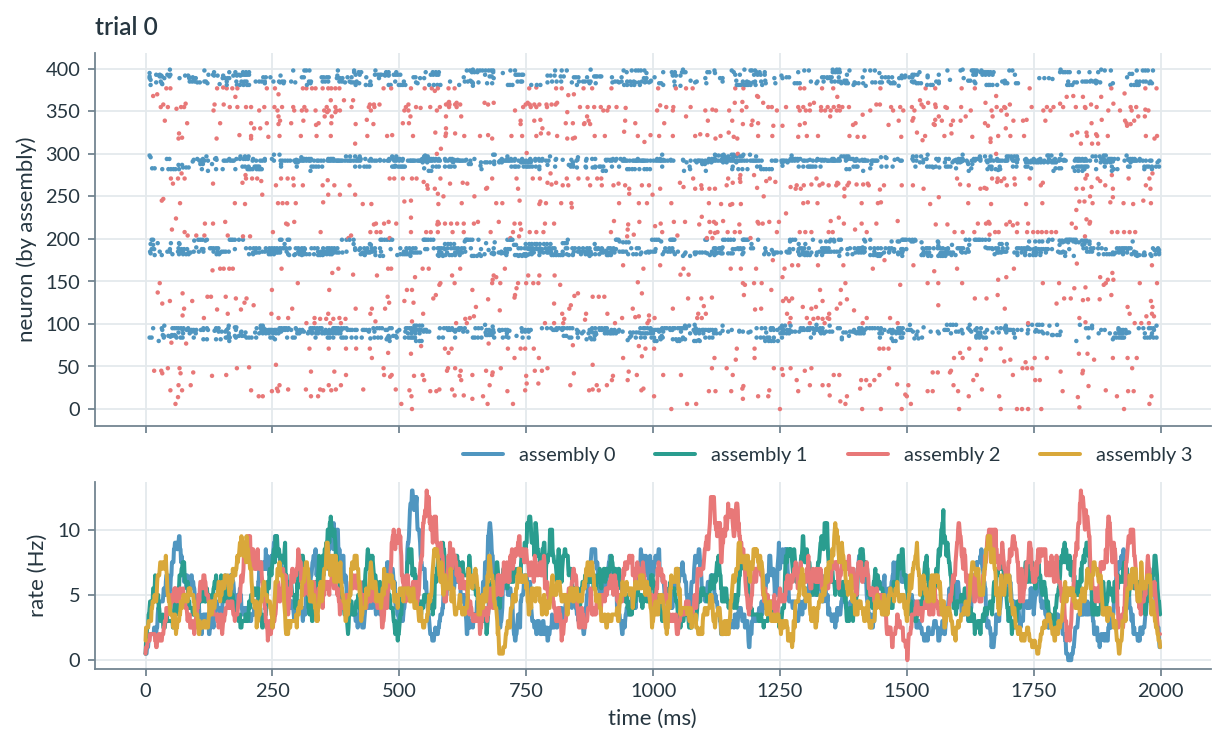
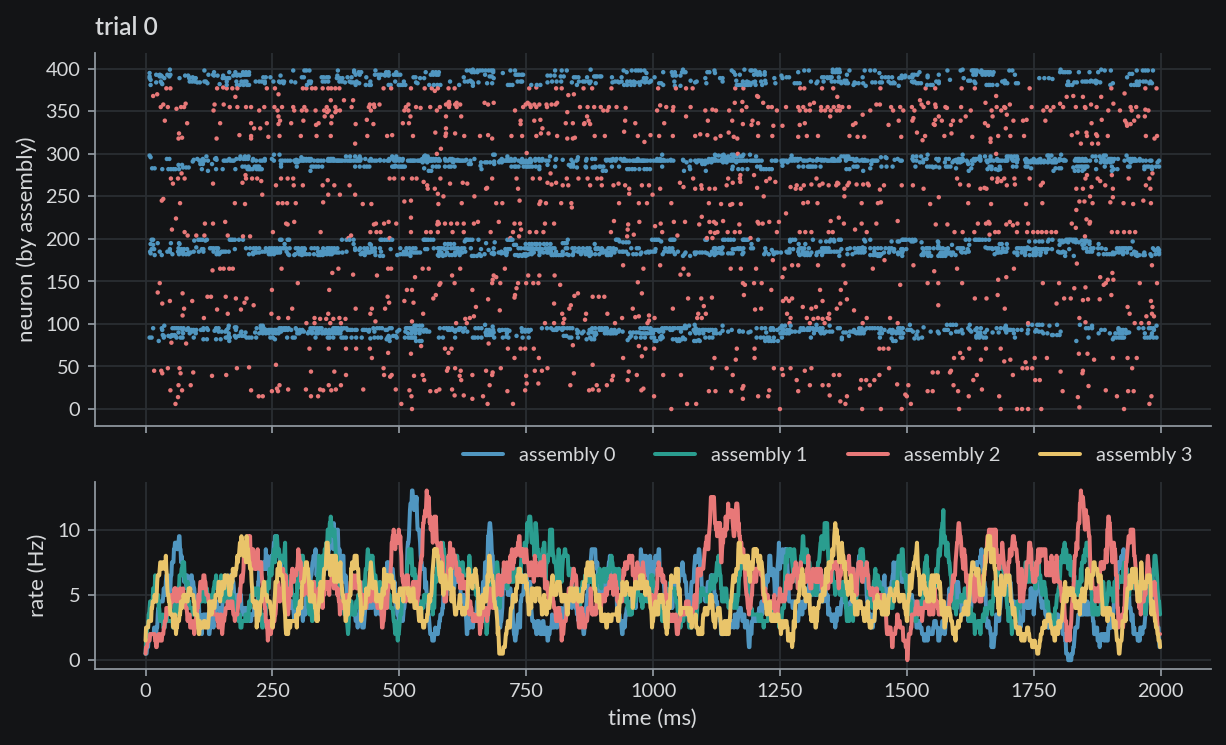

In [6]:
t = np.arange(spikes.shape[1])
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, height_ratios=[2, 1])
steps, neurons = np.nonzero(spikes[0][:, order])
a.scatter(
    steps,
    neurons,
    s=1,
    c=np.where(types[order][neurons] == E, viz.theme.EXCITATORY, viz.theme.INHIBITORY),
)
a.set_ylabel("neuron (by assembly)"), a.set_title("trial 0")
for k in range(ASSEMBLIES):
    members = assembly == k
    smooth = np.convolve(spikes[0][:, members].mean(1) * 1000, np.ones(20) / 20, "same")
    b.plot(t, smooth, label=f"assembly {k}")
(
    b.set_xlabel("time (ms)"),
    b.set_ylabel("rate (Hz)"),
    b.legend(ncol=4, loc="lower right", bbox_to_anchor=(1, 1)),
)
plt.show()

## Tracked variables

With `track_variables = True` the model also returns the voltages, synaptic currents and
conductances at every step, for one trial (`track_batch_idx`) or all of them.

{'spikes': (4, 300, 400), 'voltages': (1, 300, 400), 'currents': (1, 300, 400, 3), 'currents_leak': (1, 300, 400), 'conductances': (1, 300, 400, 2, 3)}


<Figure size 990x275 with 1 Axes>
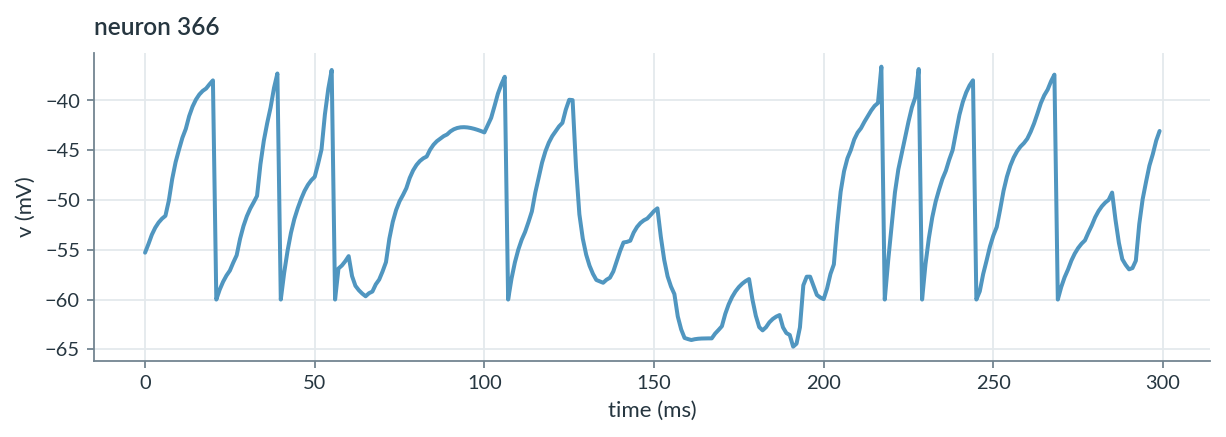
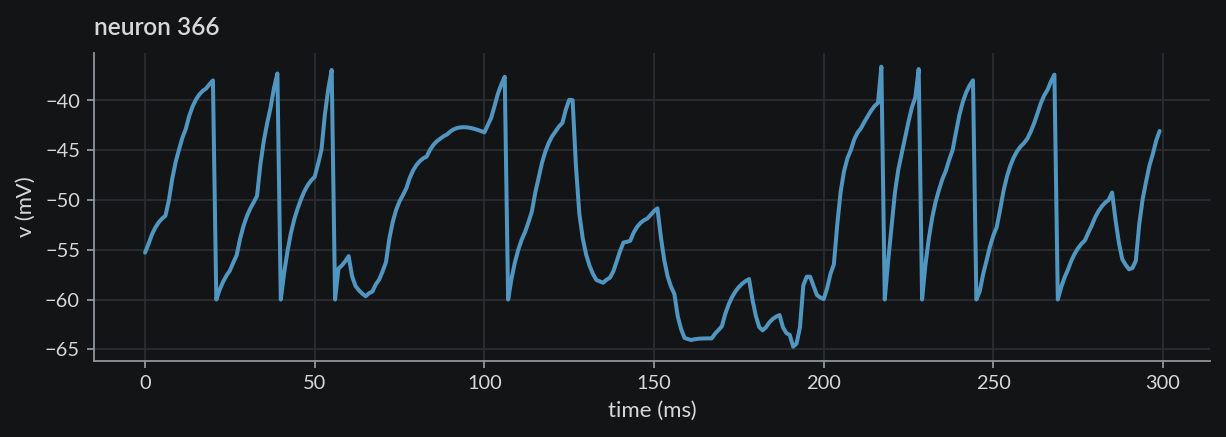

In [7]:
model.track_variables, model.track_batch_idx = True, 0
x = torch.rand(4, 300, N_IN, device=device) < 20.0 / 1000
out = model(x)
print({k: tuple(v.shape) for k, v in out.items()})

neuron = int(np.argmax(rates * (types == E)))
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.plot(out["voltages"][0, :, neuron].cpu())
ax.set_xlabel("time (ms)"), ax.set_ylabel("v (mV)"), ax.set_title(f"neuron {neuron}")
plt.show()
model.track_variables = False

## Next

{doc}`teacher_student` fits a network like this one to its own recorded spikes, and
{doc}`../concepts/projections` explains how to make the connectivity trainable.